In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, average_precision_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [14]:
file_path = "ai4i2020.csv"

df = pd.read_csv(file_path)

In [15]:
print(df.head())
print(df.info())
print(df.describe())

   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   
3                    1433         39.5                7                0    0   
4                    1408         40.0                9                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  
1    0    0    0    0  
2    0  

In [16]:
print(df.isnull().sum())

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


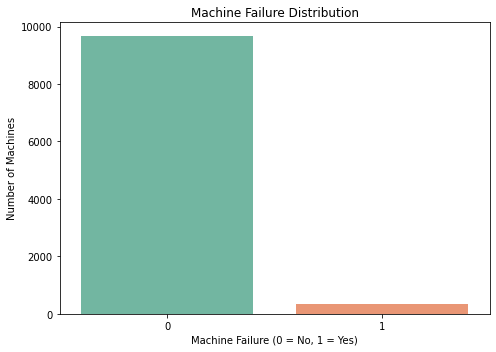

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


In [17]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Machine failure", hue="Machine failure",
              legend=False, palette="Set2")

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of Machines")
plt.tight_layout()
plt.show()

print(df["Machine failure"].value_counts(normalize=True) * 100)

Rare Failure Modes Count:
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


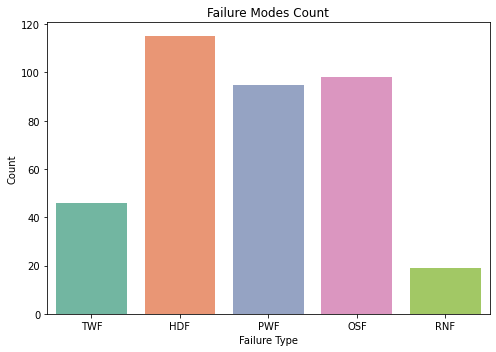

In [18]:
failure_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]
failure_counts = df[failure_cols].sum()
print("Rare Failure Modes Count:")
print(failure_counts)

plt.figure(figsize=(7, 5))
sns.barplot(x=failure_counts.index, y=failure_counts.values, hue=failure_counts.index, legend=False, palette="Set2")
plt.title("Failure Modes Count")
plt.xlabel("Failure Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [19]:
# Convert Type column from text to numbers
df["Type"] = df["Type"].map({"L": 0, "M": 1, "H": 2})

# Drop ID columns and failure mode columns to prevent target leakage
X = df.drop(columns=["UDI", "Product ID", "Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"])
y = df["Machine failure"]

# Split into training and testing sets (stratified for imbalanced data)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (8000, 6)
Testing data shape: (2000, 6)


In [20]:
log_model = LogisticRegression(random_state=42)
log_model.fit(X_train_scaled, y_train)

y_pred_log = log_model.predict(X_test_scaled)
y_prob_log = log_model.predict_proba(X_test_scaled)[:, 1]

print("Baseline Logistic Regression Results:")
print("Accuracy:", accuracy_score(y_test, y_pred_log))
print("Recall:", recall_score(y_test, y_pred_log))
print("Precision:", precision_score(y_test, y_pred_log))
print("F1 Score:", f1_score(y_test, y_pred_log))
print("PR-AUC:", average_precision_score(y_test, y_prob_log))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_log))

Baseline Logistic Regression Results:
Accuracy: 0.9675
Recall: 0.10294117647058823
Precision: 0.6363636363636364
F1 Score: 0.17721518987341772
PR-AUC: 0.42380480543011556
Confusion Matrix:
 [[1928    4]
 [  61    7]]


In [21]:
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "KNN": KNeighborsClassifier()
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    false_alarm_rate = fp / len(y_test)

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "F1": round(f1_score(y_test, y_pred), 4),
        "PR-AUC": round(average_precision_score(y_test, y_prob), 4),
        "Missed Failures (FN)": fn,
        "False Alarms (FP)": fp,
        "False Alarms per Unit": round(false_alarm_rate, 4)
    })

# Isolation Forest (Anomaly Detection)
iso = IsolationForest(contamination=0.034, random_state=42)
iso.fit(X_train_scaled)

# Convert -1 (anomaly) to 1 (failure) and 1 (normal) to 0
y_pred_iso = iso.predict(X_test_scaled)
y_pred_iso = np.where(y_pred_iso == -1, 1, 0)
y_score_iso = -iso.decision_function(X_test_scaled)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_iso).ravel()

results.append({
    "Model": "Isolation Forest",
    "Accuracy": round(accuracy_score(y_test, y_pred_iso), 4),
    "Recall": round(recall_score(y_test, y_pred_iso), 4),
    "Precision": round(precision_score(y_test, y_pred_iso), 4),
    "F1": round(f1_score(y_test, y_pred_iso), 4),
    "PR-AUC": round(average_precision_score(y_test, y_score_iso), 4),
    "Missed Failures (FN)": fn,
    "False Alarms (FP)": fp,
    "False Alarms per Unit": round(fp / len(y_test), 4)
})

comparison_df = pd.DataFrame(results)
print(comparison_df)

                 Model  Accuracy  Recall  Precision      F1  PR-AUC  \
0  Logistic Regression    0.9675  0.1029     0.6364  0.1772  0.4238   
1        Decision Tree    0.9775  0.6765     0.6667  0.6715  0.4620   
2        Random Forest    0.9840  0.6176     0.8750  0.7241  0.8135   
3    Gradient Boosting    0.9865  0.6912     0.8868  0.7769  0.8126   
4                  KNN    0.9740  0.2941     0.8333  0.4348  0.4586   
5     Isolation Forest    0.9435  0.1324     0.1429  0.1374  0.1208   

   Missed Failures (FN)  False Alarms (FP)  False Alarms per Unit  
0                    61                  4                 0.0020  
1                    22                 23                 0.0115  
2                    26                  6                 0.0030  
3                    21                  6                 0.0030  
4                    48                  4                 0.0020  
5                    59                 54                 0.0270  


Best Parameters: {'max_depth': None, 'n_estimators': 100}


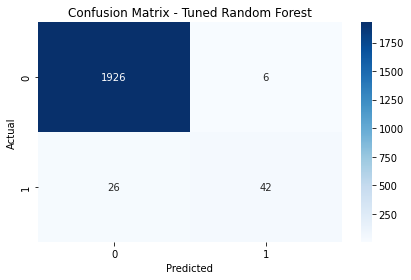

In [22]:
param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [5, 10, None]
}

grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=3, scoring="f1")
grid.fit(X_train_scaled, y_train)

best_rf = grid.best_estimator_
print("Best Parameters:", grid.best_params_)

y_pred_best = best_rf.predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Tuned Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [23]:
# Assume Missed Failure (FN) cost = 500 and False Alarm (FP) cost = 50
y_prob_best = best_rf.predict_proba(X_test_scaled)[:, 1]

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
threshold_results = []

for t in thresholds:
    preds = (y_prob_best >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()

    total_cost = (fn * 500) + (fp * 50)

    threshold_results.append({
        "Threshold": t,
        "Recall": round(recall_score(y_test, preds), 4),
        "Precision": round(precision_score(y_test, preds, zero_division=0), 4),
        "Missed Failures (FN)": fn,
        "False Alarms (FP)": fp,
        "Total Cost": total_cost
    })

threshold_df = pd.DataFrame(threshold_results)
print("Alert Threshold Report:")
print(threshold_df)

Alert Threshold Report:
   Threshold  Recall  Precision  Missed Failures (FN)  False Alarms (FP)  \
0        0.1  0.8824     0.3974                     8                 91   
1        0.2  0.8382     0.5644                    11                 44   
2        0.3  0.7794     0.6974                    15                 23   
3        0.4  0.7353     0.8333                    18                 10   
4        0.5  0.6176     0.8750                    26                  6   
5        0.6  0.5588     0.8837                    30                  5   
6        0.7  0.3971     1.0000                    41                  0   

   Total Cost  
0        8550  
1        7700  
2        8650  
3        9500  
4       13300  
5       15250  
6       20500  


In [24]:
# Save model and scaler
joblib.dump(best_rf, "best_rf_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print("Model saved successfully!")

# Load model and test on a new sample machine
loaded_model = joblib.load("best_rf_model.pkl")
loaded_scaler = joblib.load("scaler.pkl")

# Sample values: [Type, Air temp, Process temp, Rotational speed, Torque, Tool wear]
new_machine = [[0, 300.0, 310.0, 1400, 60.0, 200]]
new_machine_scaled = loaded_scaler.transform(new_machine)

prediction = loaded_model.predict(new_machine_scaled)
probability = loaded_model.predict_proba(new_machine_scaled)[:, 1]

print("New Machine Prediction (0 = No Failure, 1 = Failure):", prediction[0])
print("Failure Probability:", round(probability[0] * 100, 2), "%")

Model saved successfully!
New Machine Prediction (0 = No Failure, 1 = Failure): 1
Failure Probability: 55.0 %


c:\Users\krisha goti\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
